## CA1-STATISTICAL-TECHNIQUES

**This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.**

In [1]:
#import library packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [2]:
df = pd.read_csv("online_retail.csv")

In [3]:
df.shape

(541909, 8)

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
# I decided to remove just the observations which contain missing values in the Description columns
# No need to do the same in the CustomerID variable - in this case

df = df.dropna(subset=["Description"])

In [7]:
df.shape

(540455, 8)

In [8]:
df["UnitPrice"].describe()

count    540455.000000
mean          4.623519
std          96.889628
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

### We noticed that the Retail Company does not sell expensive products (median 2.08)

### The dataset contains negative and null UnitPrice values, which will be analyzed now

In [9]:
df[df["UnitPrice"] <= 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535336,581213,22576,check,-30,2011-12-07 18:38:00,0.0,NaN,United Kingdom
536908,581226,23090,missing,-338,2011-12-08 09:56:00,0.0,NaN,United Kingdom
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom


In [10]:
df[df["Description"] == "Adjust bad debt"].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [11]:
df = df[df["Description"] != "Adjust bad debt"]

df = df[df["UnitPrice"] > 0]

df[df["UnitPrice"] <= 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


### We removed "Adjust bad debt", since they do not represent regular product sales.

### We also identified a small number of observations related to administrative entries, such as "Manual" and "AMAZON FEE". These records were considered dataset limitations rather than data errors, and their potential impact on the statistical analysis was acknowledged.

### We identified negative values in the UnitPrice variable, which may represent accounting adjustments rather than actual product prices. As our analysis focuses on product sales, we decided to exclude these observations.

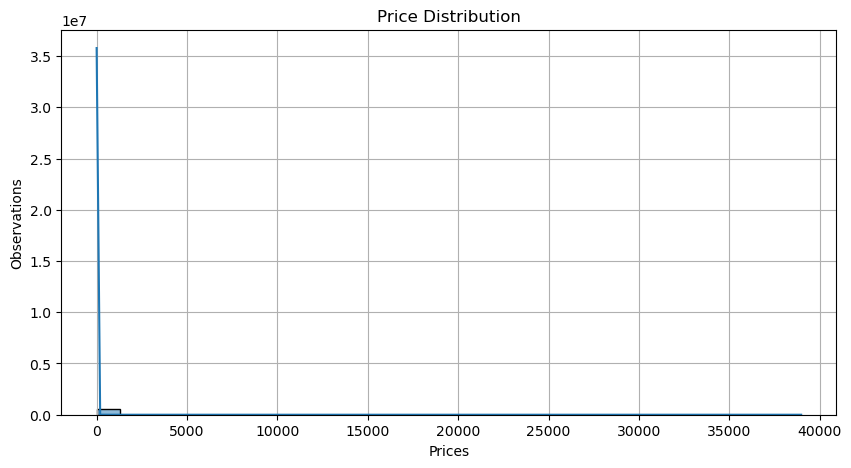

In [22]:
# Ploting normal distribution using UnitPrice
plt.figure(figsize=(10, 5))
sns.histplot(df['UnitPrice'], bins=30, kde=True)
plt.title('Price Distribution')
plt.xlabel('Prices')
plt.ylabel('Observations')
plt.grid()
plt.show()

In [13]:
df_view = df[df["UnitPrice"] <= 20]

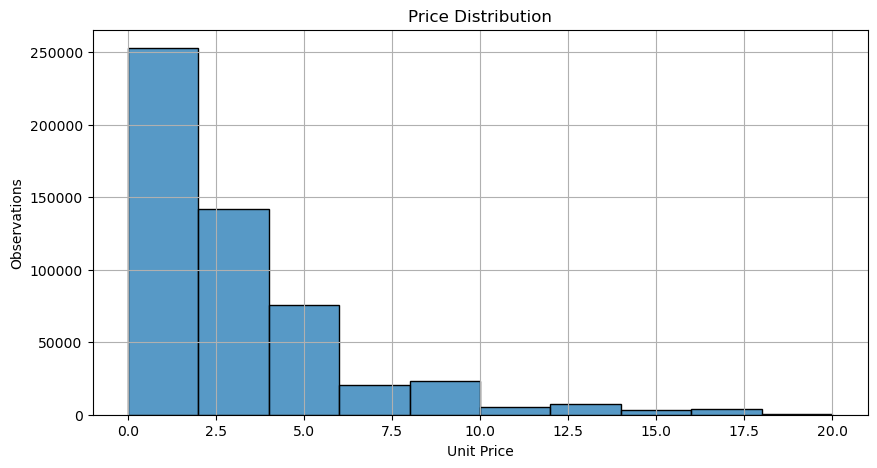

In [14]:
# Plotting UnitPrice Distribution
# For this graphic we created a new paramether, just products which cost under 20
# It was done because the dataset is very right skewed and it facilitates our visualization

plt.figure(figsize=(10, 5))
sns.histplot(df_view['UnitPrice'], bins=10, kde=False)
plt.title('Price Distribution')
plt.xlabel('Unit Price')
plt.ylabel('Observations')
plt.grid()
plt.show()

## Graph understanding

## The majority of the products cost between 0.1 and 5.0 for the unit

### Plotting UnitPrice Distribution
### For this graphic we created a new paramether, just products which cost under 20, done because the dataset is very right skewed
### Removing UK because, since the company is based in UK and domating, hidding anothers

### In the step after, it showed the needing to reduce the number of the Countries included in the analysis

In [15]:
df["Country"].value_counts().head(10)

Country
United Kingdom    492978
Germany             9493
France              8556
EIRE                8192
Spain               2532
Netherlands         2367
Belgium             2069
Switzerland         2001
Portugal            1519
Australia           1256
Name: count, dtype: int64

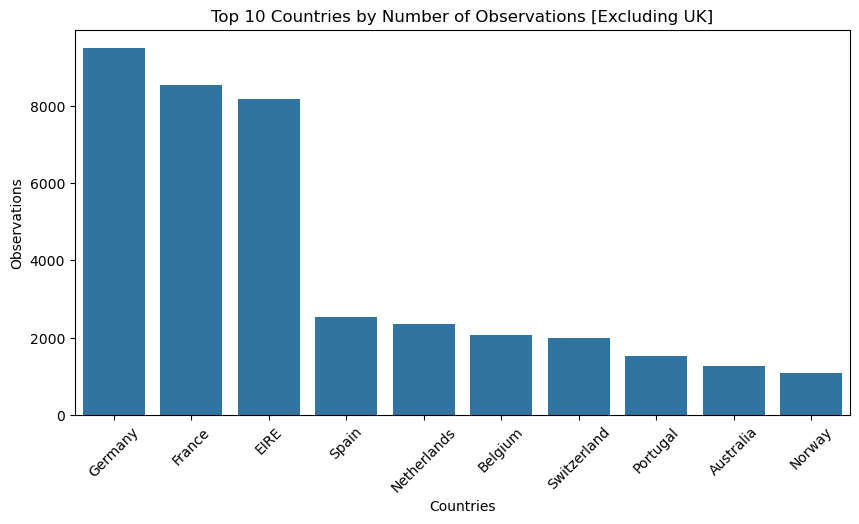

In [16]:
## What countries ordered more products

df_copy = df[df["Country"] != "United Kingdom"]
top10 = df_copy["Country"].value_counts().head(10).index

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Country", order=top10)
plt.title("Top 10 Countries by Number of Observations [Excluding UK]")
plt.xlabel("Countries")
plt.ylabel("Observations")
plt.xticks(rotation=45)
plt.show()

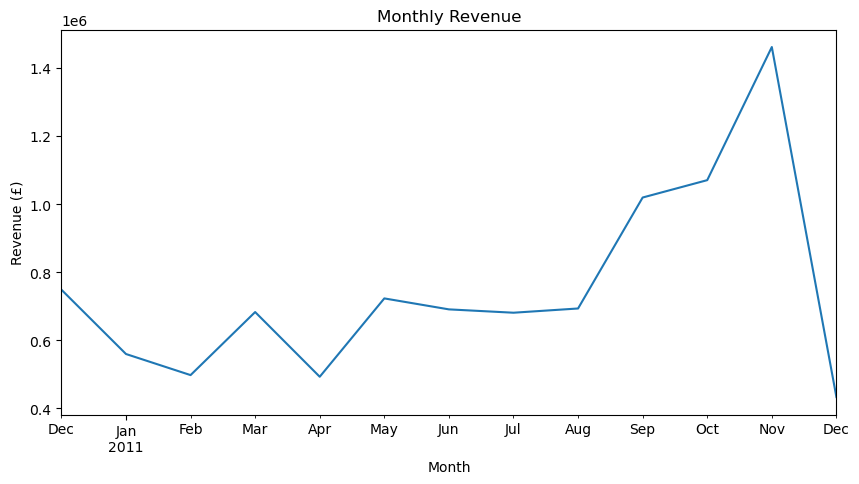

In [17]:
# Exploring new concept - pd.to_datetime() and dt.to_period(Month) - To fix our data dateformat 
# Convert InvoiceDate to datetime format

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Calculate Revenue

df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()
monthly_revenue.plot(kind="line", figsize=(10, 5))

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.show()

## Binomial Distribution
Out of 10 randomly selected transaction observations, how many are expected to come from the United Kingdom

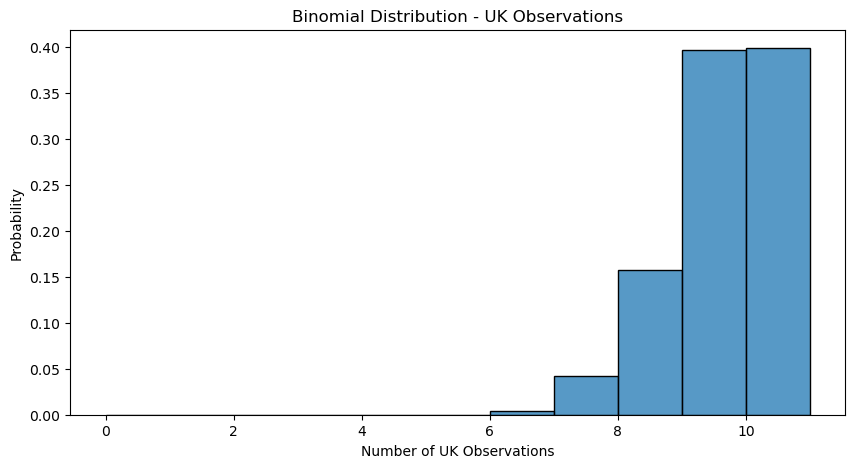

In [18]:
# Define success: observation from United Kingdom
successful_orders = df["Country"] == "United Kingdom"

# Estimating probability of success
p_success = np.mean(successful_orders)

# Defining number of trials
n_trials = 10

# Generate binomial distribution data
binomial_data = np.random.binomial(n_trials, p_success, 1000)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(binomial_data, bins=range(n_trials + 2),kde=False, stat="probability")
plt.title("Binomial Distribution - UK Observations")
plt.xlabel("Number of UK Observations")
plt.ylabel("Probability")
plt.show()

### This graph show was - as expected - the UK dominance (Headquarter is in UK)
#### Between 10 observations - the probability of 9 of than be from UK is almost 38%
#### The probability of all of than be from UK is almost 42%


# Poisson Distribution

In [19]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Count unique orders per recorded hour
hourly_orders = df.groupby(df["InvoiceDate"].dt.floor("h"))["InvoiceNo"].nunique()

# Calculate average orders per recorded hour
lambda_rate = hourly_orders.mean()

print(lambda_rate)

8.135384615384615


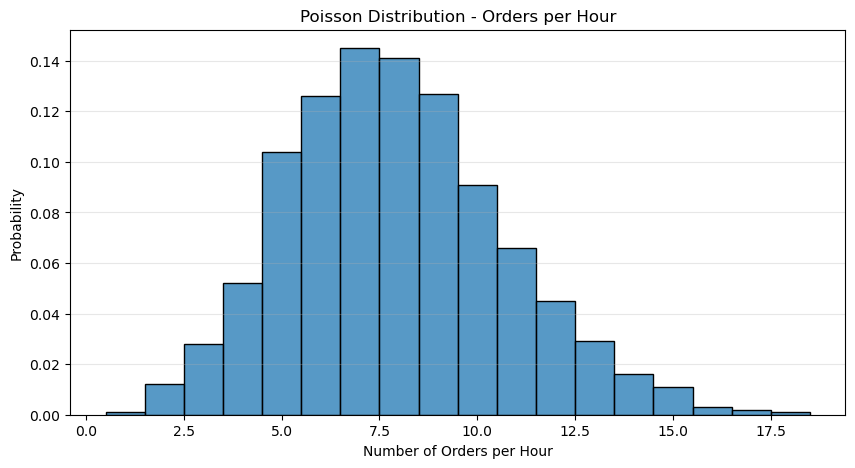

In [20]:
poisson_data = np.random.poisson(lambda_rate, 1000)

plt.figure(figsize=(10, 5))
sns.histplot(poisson_data, discrete=True, stat="probability")

plt.title("Poisson Distribution - Orders per Hour")
plt.xlabel("Number of Orders per Hour")
plt.ylabel("Probability")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Normal Distribution

### We can use normal distribution to see, how many quantities of product any observation (transaction) has
### Usefull to see - when a costumer buy a product, how many quantities of it is acquired
### Number 150 defined to facilitate the view  - since the average of the abservations are in this gap

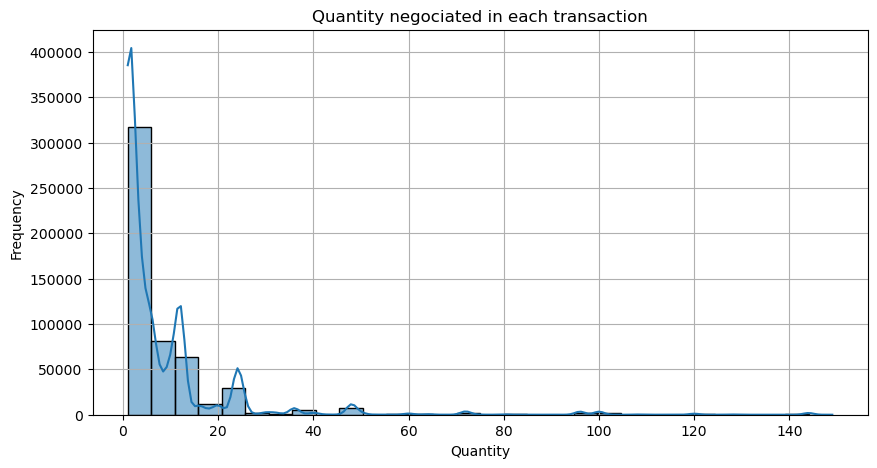

In [21]:
df_view1 = df[(df["Quantity"] > 0) & (df["Quantity"] < 150)]

# Plot normal distribution using Quantities
plt.figure(figsize=(10, 5))
sns.histplot(df_view1['Quantity'], bins=30, kde=True)
plt.title('Quantity negociated in each transaction')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.grid()
plt.show()

## The reason to choose "Quantity negociated in each transaction" was: with this information, we can see the average amount of buys we have in each transaction - understing the public/niche we must focus our marketing strategies (small business, medium/big size companies, multinacional buyer/distributor)